# 01 · Text data: from 5 raw sources to one clean, balanced dataset

**Goal:** build the dataset for the 3-class sentiment models (negative / neutral / positive).

**Inputs:** `data/raw/text/` (downloaded by `scripts/download_data.py text`)
- Lecturer: Amazon Review (one memory card), Customer Feedback (external test only)
- Amazon Reviews 2023: Electronics and Grocery samples (300k reviews each, random chunks)
- Flipkart product reviews

**Outputs:** `data/processed/text_{train,val,test,external_test}.csv`, count tables in `results/`, figures in `results/figures/`.

All logic lives in `src/data_text.py` and `src/preprocess_text.py`; this notebook only calls it and shows results.

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))  # make `src` importable from notebooks/

import pandas as pd
from IPython.display import Image, display
pd.set_option("display.max_colwidth", 120)
pd.set_option("display.width", 200)

## 1. What does each raw source look like?

In [2]:
from src.data_text import describe_raw_sources
describe_raw_sources()

,role,category,rows,columns,stars 1/2/3/4/5 (%)
source,,,,,
amazon_lecturer,train,electronics,4915,"reviewerID, asin, reviewerName, helpful, reviewText, overall, summary, unixReviewTime, reviewTime, day_diff, helpful...",5% / 2% / 3% / 11% / 80%
customer_feedback,external_test,other,96,"review_id, source, category, text, rating, label",no stars
flipkart,train,other,205052,"product_name, product_price, Rate, Review, Summary, Sentiment",10% / 3% / 8% / 20% / 58%
amazon2023_electronics,train,electronics,300000,"rating, title, text, images, asin, parent_asin, user_id, timestamp, helpful_vote, verified_purchase",12% / 5% / 7% / 13% / 63%
amazon2023_grocery,train,grocery,300000,"rating, title, text, images, asin, parent_asin, user_id, timestamp, helpful_vote, verified_purchase",13% / 5% / 6% / 9% / 67%


Every source with stars is mostly **positive** (60–80% five stars). Without balancing, a model
could score ~75% accuracy by always answering "positive", so balancing matters.

## 2. Two traps found while inspecting the data

**Trap 1: Flipkart's `Review` column is not written by customers.** Flipkart fills it in from
the star rating. The table shows each common value almost always goes with one rating:

In [3]:
from src.data_text import flipkart_title_leak
flipkart_title_leak()

Rate,1,2,3,4,5
Review,,,,,
awesome,0,0,2,10,5624
best in the market!,1,0,0,5,5540
brilliant,7,2,0,5,5629
classy product,3,2,2,4,5591
great product,4,0,1,4,5613
must buy!,1,0,2,8,5566
not specified,932,280,881,1683,4575
perfect product!,4,1,2,5,5588
simply awesome,3,2,3,4,5583


If we trained on it, the model would learn to *read the star rating*, not the sentiment, and
look great on paper. So for Flipkart we use only the `Summary` column (the customer's own words).

**Trap 2: Amazon's automatic titles.** ~11% of Amazon 2023 reviews have titles like "Five Stars",
generated from the rating. We drop those titles and keep the body text.

In [4]:
from src.data_text import combine_title_body
print(combine_title_body("Five Stars", "Works fine, fast shipping"))
print(combine_title_body("Does not work", "Tried several configurations"))

Works fine, fast shipping
Does not work. Tried several configurations


## 3. Labelling, cleaning, deduplication, balancing, splitting

One rule for every source with stars: **1–2 = negative, 3 = neutral, 4–5 = positive**.
Customer Feedback has no stars, so it keeps its own labels; it is used only as an external test.

Cleaning steps (in order): drop rows without a valid label → drop texts under 3 words →
drop texts that appear with *different* labels (ambiguous) → drop duplicates (on normalised
text, across all sources, so a review can't be in both train and test).

In [5]:
from src.data_text import build_text_dataset
data = build_text_dataset(save=True, verbose=False)
print("Raw counts per source and label:")
display(data["raw_counts"])
print("What each cleaning step removed:")
display(data["clean_log"])

Raw counts per source and label:


label,negative,neutral,no label,positive,total
source,,,,,
amazon2023_electronics,51863,19962,0,228175,300000
amazon2023_grocery,53317,18593,0,228090,300000
amazon_lecturer,324,142,0,4449,4915
customer_feedback,43,0,0,53,96
flipkart,27791,16599,3,160659,205052
total,133338,55296,3,621426,810063


What each cleaning step removed:


,step,removed,left
0,no valid label,3,809964
1,< 3 words,122581,687383
2,"same text, different labels",13561,673822
3,duplicate text,32297,641525


**Balancing:** downsample to 15,000 reviews per class, shared fairly across sources, and within
each source no class may be more than 3× its smallest class (so the model can't learn shortcuts
like "Flipkart style = negative" or "memory card = positive").

In [6]:
print("After cleaning:")
display(data["clean_counts"])
print("After balancing:")
display(data["balanced_counts"])
print("Split sizes (70/15/15, stratified by label and source):")
display(data["split_counts"])

After cleaning:


label,negative,neutral,positive,total
source,,,,
amazon2023_electronics,49956,19118,204696,273770
amazon2023_grocery,51861,17872,207079,276812
amazon_lecturer,324,142,4436,4902
flipkart,16479,7153,62409,86041
total,118620,44285,478620,641525


After balancing:


label,negative,neutral,positive,total
source,,,,
amazon2023_electronics,4892,4952,4858,14702
amazon2023_grocery,4892,4953,4858,14703
amazon_lecturer,324,142,426,892
flipkart,4892,4953,4858,14703
total,15000,15000,15000,45000


Split sizes (70/15/15, stratified by label and source):


,train,val,test
label,,,
negative,10499,2251,2250
neutral,10499,2251,2250
positive,10501,2248,2251


## 4. Two preprocessing paths

- **Classical models** (Naive Bayes, TF-IDF + LR) only count words → lowercase, remove punctuation,
  remove stopwords **but keep negations** ("not good" must not become "good"), lemmatise.
- **Transformers** (MiniLM, DistilBERT, RoBERTa) read full sentences → light cleaning only (HTML, URLs).

In [7]:
data["train"][["label", "text", "text_classical"]].sample(6, random_state=42)

,label,text,text_classical
6994,neutral,Nice snack. I enjoyed the crispy cookie mixed with a strawberry filling. They really went well together. No part ove...,nice snack enjoyed crispy cookie mixed strawberry filling really went well together no part overpowered similar stra...
3964,neutral,Melting Chocolate Strawberries. They weren’t in top shape,melting chocolate strawberry weren top shape
16128,positive,very good for steaching and designing,very good steaching designing
20762,negative,Missing parts! I just opened this tv on Christmas morning! It did not come with TV leg stands or even a remote! High...,missing part opened tv christmas morning not come tv leg stand even remote highly dissatisfied
4339,negative,not working very bad,not working very bad
5472,negative,Taste is okay but not great. This does not help me sleep unfortunately,taste okay but not great not help sleep unfortunately


## 5. Exploratory figures

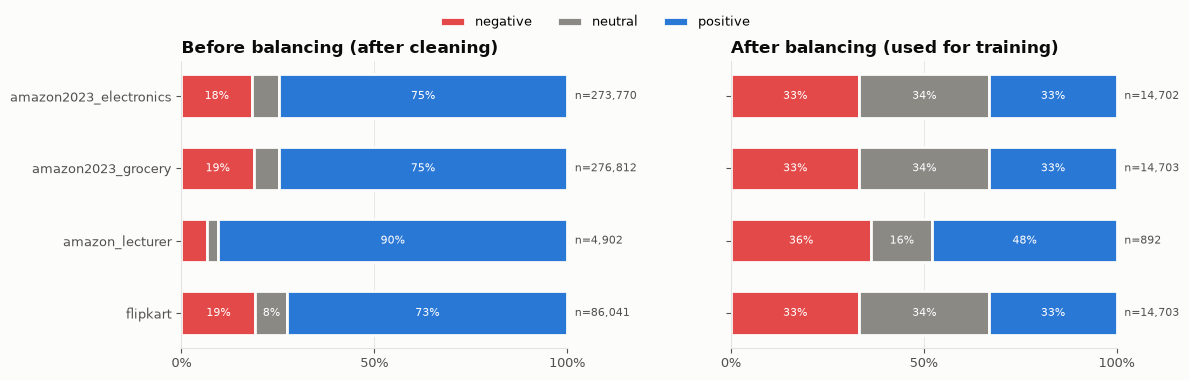

In [8]:
from src.eda import plot_class_balance
plot_class_balance(data["clean_counts"], data["balanced_counts"]);

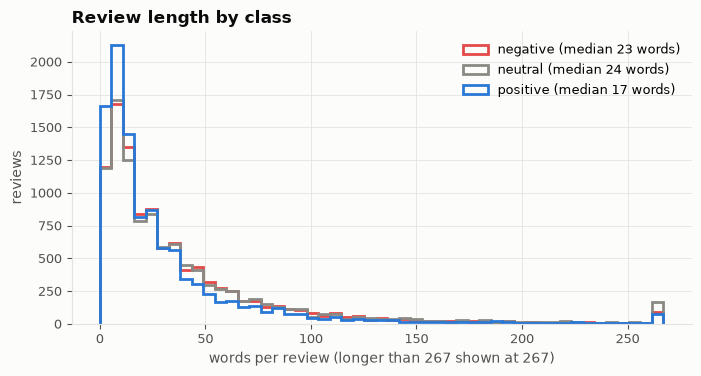

In [9]:
from src.eda import plot_length_distribution
plot_length_distribution(data["train"]);

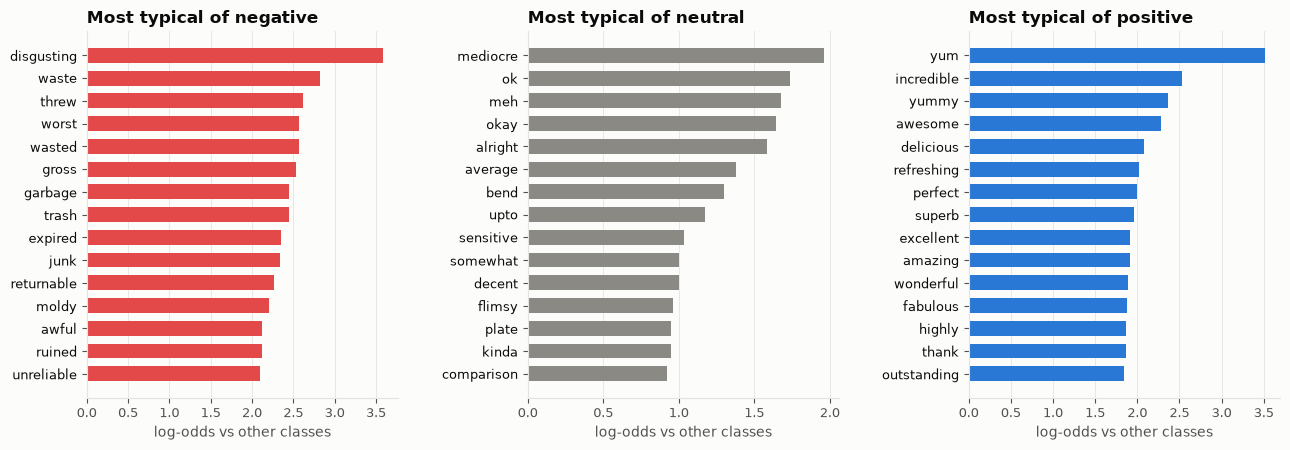

In [10]:
from src.eda import plot_distinctive_words
plot_distinctive_words(data["train"]);

## 6. Spot-check: example reviews per source and class

In [11]:
from src.eda import sample_reviews
sample_reviews(data["train"], n=1)

,source,label,rating,text
20762,amazon2023_electronics,negative,1.0,Missing parts! I just opened this tv on Christmas morning! It did not come with TV leg stands or even a remote! High...
1197,amazon2023_electronics,neutral,3.0,Tight fit. Just barely big enough to fit my Samsung camera into. Once the camera is in there isn't much room for any...
7267,amazon2023_electronics,positive,5.0,"The king of USB-C Hubs. Honestly, ACASIS’s 10-in-1 USB-C Hub is like the king of all hubs. Purchased: March 2022. Po..."
5472,amazon2023_grocery,negative,1.0,Taste is okay but not great. This does not help me sleep unfortunately
6994,amazon2023_grocery,neutral,3.0,Nice snack. I enjoyed the crispy cookie mixed with a strawberry filling. They really went well together. No part ove...
31449,amazon2023_grocery,positive,5.0,"Sweet with mild Sour. I wouldn't consider these super sour, but they are nice and sweet with light sour kick to them..."
11118,amazon_lecturer,negative,1.0,Similar to the other 492 users: Worked great for about 2 months... UPDATE:This card stopped working as of late Febru...
12622,amazon_lecturer,neutral,3.0,Very nice. I thought every app could be transferred into the sd card but no. The description said that I would speed...
5803,amazon_lecturer,positive,5.0,"No problems yet, works fine in htc sensation, it seems kinda slow but I'm thinking it's a problem with my phone inte..."
4339,flipkart,negative,1.0,not working very bad


## 7. External test set (Customer Feedback)

In [12]:
ext = data["external_test"]
print(len(ext), "reviews after removing duplicates")
display(ext["label"].value_counts())
ext[["label", "text"]].head(8)

75 reviews after removing duplicates


label
positive    42
negative    33
Name: count, dtype: int64

,label,text
0,positive,I love this product!
1,negative,The service was terrible.
2,positive,This movie is amazing!
3,negative,I'm so disappointed with their customer support.
4,positive,Just had the best meal of my life!
5,negative,The quality of this product is subpar.
6,positive,I can't stop listening to this song. It's incredible!
7,positive,Their website is so user-friendly. Love it!


## Key findings

- **5 sources, 810k raw reviews → 641k after cleaning → 45,000 balanced** (15k per class): 31,499 train / 6,750 val / 6,751 test.
- **Two label leaks were found and removed**: Flipkart's rating-generated `Review` titles and Amazon's automatic "Five Stars" titles. Keeping them would have inflated accuracy without the model really understanding sentiment.
- Raw data is heavily skewed to positive (60–80% five stars), so balancing is essential; neutral (3 stars) is the rarest and hardest class.
- Negative and neutral reviews are longer than positive ones (median 23–24 vs 17 words): unhappy customers explain what went wrong.
- The most typical negative words (waste, threw, garbage, expired, moldy, returnable) point at concrete problems, which is exactly what the issue tagger and the fusion step build on. Neutral reviews are recognisable by hedging words (ok, meh, average, decent, somewhat, kinda).
- The external Customer Feedback set is tiny (75 reviews after removing duplicates: 42 positive, 33 negative), has only positive/negative labels and is mostly not about products (music, films, restaurants), so it is a test of how well the model handles **unfamiliar text**, scored on positive vs negative only.